In [1]:
from Bio import SeqIO
from Bio import Align

def show_ends(seq, n = 20):
    return str(seq[:n+1]) + ' ... ' + str(seq[-n:])

In [2]:
for record in SeqIO.parse('../../../datasets/phage/phage_identification/reference_genomes/phi80.fasta', "fasta"):
    phi80_genome = record.seq
    
for record in SeqIO.parse('../../../datasets/phage/phage_identification/reference_genomes/T1.fasta', "fasta"):
    T1_genome = record.seq

In [3]:
for record in SeqIO.parse('../../../datasets/phage/phage_identification/sequencing/7XNRV9_2_phage_ED05.fasta', "fasta"):
    ED05_genome = record.seq

In [4]:
import pandas as pd
import numpy as np

gene_map_raw = pd.read_csv('../../../datasets/phage/phage_identification/phi80_gene_map_raw.tsv', sep = '\t')

# Identify the rearrangements

In [5]:
global_aligner = Align.PairwiseAligner()
global_aligner.mismatch_score = 0   # Penalty for mismatches
global_aligner.open_gap_score = -1   # Penalty for opening a gap

local_aligner = Align.PairwiseAligner()
local_aligner.mode = 'local'
local_aligner.mismatch_score = 0   # Penalty for mismatches
local_aligner.open_gap_score = -1   # Penalty for opening a gap

half_aligner = Align.PairwiseAligner()
half_aligner.mode = 'local'
half_aligner.open_gap_score = -5      # Penalty for opening a gap
half_aligner.extend_gap_score = -0.5  # Penalty for extending a gap
half_aligner.end_gap_score = 0        # No penalty for gaps at the end

# ED05
The lytic phage isolated from the frozen sample ED05, mapped against the Phi80 reference.

In [6]:
target = phi80_genome
query = ED05_genome

In [7]:
def search_snippet(target, query, last_matched_pos, window_size = 100):
    # Search for a snippet in ref
    local_alignments = local_aligner.align(target, query[last_matched_pos:last_matched_pos + window_size])
    print(local_alignments[0])
    
    return int(local_alignments[0].aligned[0][0][0])

In [8]:
max_consecutive_mismatches = 2

def extend_matching_region(target, query, start_in_ref, start_in_query, max_consecutive_mismatches = 2):
    '''Given coordinates in target and query where a matching region starts, tell the length of this region.'''
                              
    i = 0
    consecutive_mismatches = 0
    mismatches = []

    while start_in_query + i < len(query):

        target_base = target[start_in_ref + i]
        query_base = query[start_in_query + i]

        if target_base != query_base:

            mismatches.append(f'{target_base} -> {query_base} ({start_in_query + i} in query, {start_in_ref + i} in ref)')
            consecutive_mismatches += 1

            if consecutive_mismatches > max_consecutive_mismatches:
                break
                
        else:
            consecutive_mismatches = 0

        i += 1
 
    return i - max_consecutive_mismatches - 1, mismatches[:-max_consecutive_mismatches-1]

In [9]:
last_matched_pos = 0
map_in_ref = []
map_in_query = []
all_mismatches = []

In [10]:
while last_matched_pos < len(query) - max_consecutive_mismatches:
    
    print('Searching for start of the region...')
    start_in_ref = search_snippet(target, query, last_matched_pos)
    region_length, mismatches = extend_matching_region(target, query, start_in_ref, last_matched_pos)

    end_in_ref = start_in_ref + region_length + 1
    end_in_query = last_matched_pos + region_length + 1

    map_in_query.append([last_matched_pos, end_in_query])
    map_in_ref.append([start_in_ref, end_in_ref])

    print()
    print(f'Query {last_matched_pos}:{end_in_query} matches target {start_in_ref}:{end_in_ref}')
    print(show_ends(query[last_matched_pos: end_in_query]))
    print(show_ends(target[start_in_ref: end_in_ref]))
    print()
    
    if mismatches:
        print('Mismatches:')
        print('\n'.join(mismatches) + '\n')
        all_mismatches += mismatches

    last_matched_pos = end_in_query

Searching for start of the region...
target           37 TTTTCAGGCATTTGCCGTTTCCGTTCTTCTTCTCGCTAATTCATTGTTTTAACTGTAAAC
                  0 ||||||||||||||||||||||||||||||||||||||||||||||||||||||||||||
query             0 TTTTCAGGCATTTGCCGTTTCCGTTCTTCTTCTCGCTAATTCATTGTTTTAACTGTAAAC

target           97 ACCCCCTGAAAAGAAAGGAAATGATAAGCCTTAAAAACGG 137
                 60 |||||||||||||||||||||||||||||||||||||||| 100
query            60 ACCCCCTGAAAAGAAAGGAAATGATAAGCCTTAAAAACGG 100


Query 0:33204 matches target 37:33241
TTTTCAGGCATTTGCCGTTTC ... GATTTGTAGGTCAACACCAT
TTTTCAGGCATTTGCCGTTTC ... GATTTGTAGGTCAACACCTT

Mismatches:
A -> C (20352 in query, 20389 in ref)
A -> G (22293 in query, 22330 in ref)
T -> A (33202 in query, 33239 in ref)

Searching for start of the region...
target        35355 AATGTTGATTTAATCCACGCCATGAATTAACATGGTGTTGATTACACATGAGCGGAGCAA
                  0 ||||||||.|||||||||||||||||||||||||||||||||||||||||||||||||||
query             0 AATGTTGACTTAATCCACGCCATGAATTAACATGGTGTTGATT

In [11]:
for i, j in zip(map_in_query, map_in_ref):
    print(f'{i} in query = {j} in reference')

print()
print('Mismatches:')
print('\n'.join(all_mismatches))

[0, 33204] in query = [37, 33241] in reference
[33204, 35891] in query = [35355, 38042] in reference
[35891, 45957] in query = [36026, 46092] in reference

Mismatches:
A -> C (20352 in query, 20389 in ref)
A -> G (22293 in query, 22330 in ref)
T -> A (33202 in query, 33239 in ref)
T -> C (33212 in query, 35363 in ref)


The mismatches are in:
* gp22/gp24 homologous
* mosaic tail fiber protein
* oL2
* oR2

The gp22 protein (called PHI80_22 in genomics data) is exactly the one that's hypothesized to determine fhuA specificity...

In [12]:
pos = 20353
gene_map_raw[(gene_map_raw.raw_start <= pos) & (gene_map_raw.raw_end >= pos)]

,id,raw_start,raw_end,length,length_aa,reading_frame,product,N15_homolog,name
27,22,20210,20509,300.0,100.0,F2,"Hypothetical phage protein, identical to HK022...",gp22,gp24


# What do these regions correspond to
The phi80_gene_map file was obtained from https://pmc.ncbi.nlm.nih.gov/articles/PMC3510586/table/T1/#TF1-1 (Rotman 2012).

We have:
* Deletion of 33239:35353
* Duplication of 36026:38042.

In [13]:
gene_map_raw

,id,raw_start,raw_end,length,length_aa,reading_frame,product,N15_homolog,name
0,s,1,12,NaN,NaN,-,"GGGCGGCGACCT, sticky end",NaN,NaN
1,s,109,165,NaN,NaN,-,"Inverted repeat, AGAAAGGAAA(38 N)TTTCCTTTCT",NaN,IR1
2,1,190,732,543.0,181.0,F1,Terminase small subunit (Nu1)/lambda,gp1,Nu1
3,2,710,2629,1920.0,640.0,F2,Terminase large subunit (A)/lambda,gp2,A
4,3,2632,2835,204.0,68.0,F1,"Head-tail joining protein (W)/N15, lambda",gp3,W
...,...,...,...,...,...,...,...,...,...
101,63,44979,44368,612.0,204.0,R2,Hypothetical protein,NaN,-
102,64,44960,45187,228.0,76.0,F2,Fur-regulated protein 1,NaN,-
103,65,45528,45232,297.0,99.0,R2,Putative protein,NaN,-
104,66,45352,46077,726.0,242.0,F1,Conserved hypothetical protein/phiKO2,gp59,-


In [14]:
gene_map_raw['start'] = np.where(gene_map_raw.raw_end > gene_map_raw.raw_start, gene_map_raw.raw_start, gene_map_raw.raw_end)
gene_map_raw['end'] = np.where(gene_map_raw.raw_end > gene_map_raw.raw_start, gene_map_raw.raw_end, gene_map_raw.raw_start)
gene_map_raw['fp'] = gene_map_raw.end - gene_map_raw.start + 1

In [15]:
gene_map = gene_map_raw[['id', 'name', 'start', 'end', 'product', 'fp', 'N15_homolog', 'reading_frame']].sort_values(['start', 'end'])

In [16]:
gene_map

,id,name,start,end,product,fp,N15_homolog,reading_frame
0,s,NaN,1,12,"GGGCGGCGACCT, sticky end",12,NaN,-
1,s,IR1,109,165,"Inverted repeat, AGAAAGGAAA(38 N)TTTCCTTTCT",57,NaN,-
2,1,Nu1,190,732,Terminase small subunit (Nu1)/lambda,543,gp1,F1
3,2,A,710,2629,Terminase large subunit (A)/lambda,1920,gp2,F2
4,3,W,2632,2835,"Head-tail joining protein (W)/N15, lambda",204,gp3,F1
...,...,...,...,...,...,...,...,...
101,63,-,44368,44979,Hypothetical protein,612,NaN,R2
102,64,-,44960,45187,Fur-regulated protein 1,228,NaN,F2
103,65,-,45232,45528,Putative protein,297,NaN,R2
104,66,-,45352,46077,Conserved hypothetical protein/phiKO2,726,gp59,F1


In [17]:
gene_map.to_csv('../../../datasets/phage/phage_identification/phi80_gene_map.tsv', sep = '\t', index = False)

In [18]:
# Deleted elements
gene_map[(gene_map.end >= 33239) & (gene_map.start <= 35353)]

,id,name,start,end,product,fp,N15_homolog,reading_frame
63,s,oL2,33230,33248,oL2,19,NaN,-
65,s,oL3,33273,33292,oL3,20,NaN,-
66,46,40A,33591,34454,Protein 40A of phi80 (other phage exclusion fu...,864,NaN,R3
67,47,cI,34594,35355,CI transcriptional regulator,762,NaN,R2
68,s,pRM-10,35321,35326,"pRM, −10 box",6,NaN,-
69,s,oR3,35323,35341,oR3,19,NaN,-
70,s,pRM-35,35344,35349,"pRM, −35 box",6,NaN,-
71,s,oR2,35347,35365,oR2,19,NaN,-


In [19]:
# Duplicated elements
gene_map[(gene_map.end >= 36026) & (gene_map.start <= 38042)]

,id,name,start,end,product,fp,N15_homolog,reading_frame
76,49,cII,35671,36210,CII decision-making protein,540,NaN,F1
77,RNA,oop,36229,36288,oop RNA (M3 RNA),60,NaN,-
78,50,O,36299,37204,"Replication initiation protein (O), analog of ...",906,NaN,F2
79,s,ori,36663,36677,ori iteron 4,15,NaN,-
80,s,ori,36683,36698,ori iteron 3,16,NaN,-
81,s,ori,36704,36719,ori iteron 2,16,NaN,-
82,s,ori,36725,36739,ori iteron 1,15,NaN,-
83,51,P,37204,37890,"Replication initiation protein (P), analog of ...",687,NaN,F1
84,52,cdtI,37957,38673,Conserved hypothetical protein /CdtI,717,gp45,F1


# Make a plot

In [20]:
# Use the minimal version
gene_map = pd.read_csv('../../../datasets/phage/phage_identification/phi80_gene_map_compact.tsv', sep = '\t')

# Remove nameless features
df = gene_map[~(gene_map.name.isna())].reset_index(drop = True)

In [21]:
df[df.id == 'x']

,id,name,start,end,product,fp,N15_homolog,reading_frame
29,x,attP,24623,24639,attP (ACACTTT)CTT(AAATTGT),17,NaN,-
44,x,pL,33207,33292,pL,85,NaN,NaN
52,x,pRM,35321,35388,pR,67,NaN,NaN
64,x,ori,36663,36739,ori,80,-,NaN
72,x,pR',41989,42017,pR',30,-,NaN


In [22]:
# Deletion of 33239:35353
# Duplication of 36026:38042

pal = ["#3B9AB2", "#78B7C5", "#EBCC2A", "#E1AF00", "#F21A00"]

slack = 10 # to make sure cI is included (it has 2 bp out of the deletion)

del_start = 33239
del_end = 35353
dup_start = 36026
dup_end = 38042

# Arrow style
dup_color = pal[0]
del_color = pal[4]
other_color = "#dfe4e6"
arrow_shaft_ratio = 0.5

fc = pal[0]
lw = 1

# Text style
text_size = 22
main_text_style = dict(rotation=0, vpos = 'top', hpos = 'center', size = text_size)
alt_text_style = dict(rotation=0, vpos = 'bottom', hpos = 'center', size = text_size)

# Link style
curve = False
alpha = 0.1

zoom = 9

import pygenomeviz

gbv = pygenomeviz.GenomeViz(track_align_type="center", fig_track_height=1, feature_track_ratio=0.5)

wt_name = 'Φ80 genome'
mut_name = ''

alt_features = ['O', 'oop']

zoomed_del_len = (del_end - del_start + 1) * zoom
zoomed_dup_len = (dup_end - dup_start + 1) * zoom

# Create tracks for wild type and mutant
mut_track = gbv.add_feature_track(mut_name, [zoomed_del_len, zoomed_dup_len], space = 0.2)
wild_track = gbv.add_feature_track(wt_name, len(phi80_genome), space = 0.01)

# Add features from dataframe to wild type track
for _, row in df.iterrows():
    
    if row.id == 's': continue
    
    # Set style
    strand = 1 if str(row['reading_frame']).startswith('F') else (-1 if str(row['reading_frame']).startswith('R') else 0)
    style = 'bigarrow' if strand != 0 else 'bigbox'
    
    # Deleted features
    if row.end >= del_start - slack and row.start <= del_end + slack:
        
        color = del_color
        
        # Show on the deletion zoom
        zoomed_start = max((row.start - del_start) * zoom, 0)
        zoomed_end = min((row.end - del_start) * zoom, (del_end - del_start + 1) * zoom)
        
        mut_track.segments[0].add_feature(start=zoomed_start, end=zoomed_end, strand=strand, label=row['name'], 
                                          plotstyle=style, fc=color, lw=lw, arrow_shaft_ratio=arrow_shaft_ratio, text_kws=main_text_style)
        
        
    # Duplicated features
    elif row.end >= dup_start - slack and row.start <= dup_end + slack:
        
        color = dup_color
        text_style = main_text_style if not row['name'] in alt_features else alt_text_style
        
        # Show on the duplication zoom
        zoomed_start = max((row.start - dup_start) * zoom, 0)
        zoomed_end = min((row.end - dup_start) * zoom, (dup_end - dup_start + 1) * zoom)
        
        mut_track.segments[1].add_feature(start=zoomed_start, end=zoomed_end, strand=strand, label=row['name'], 
                                          plotstyle=style, fc=color, lw=lw, arrow_shaft_ratio=arrow_shaft_ratio, text_kws=text_style)
        
    else:
        color = other_color
    
    wild_track.add_feature(start=row['start'], end=row['end'], strand=strand, label='', 
                           plotstyle=style, arrow_shaft_ratio=arrow_shaft_ratio, fc=color, lw=lw)

# Add links
gbv.add_link((wt_name, del_start, del_end), (mut_name, 'seg1', 0, zoomed_del_len), curve = curve, alpha = alpha, size = 1.47, color = del_color)
gbv.add_link((wt_name, dup_start, dup_end), (mut_name, 'seg2', 0, zoomed_dup_len), curve = curve, alpha = alpha, size = 1.47, color = dup_color)

Text(37500.0, -2.3, 'Duplicated')

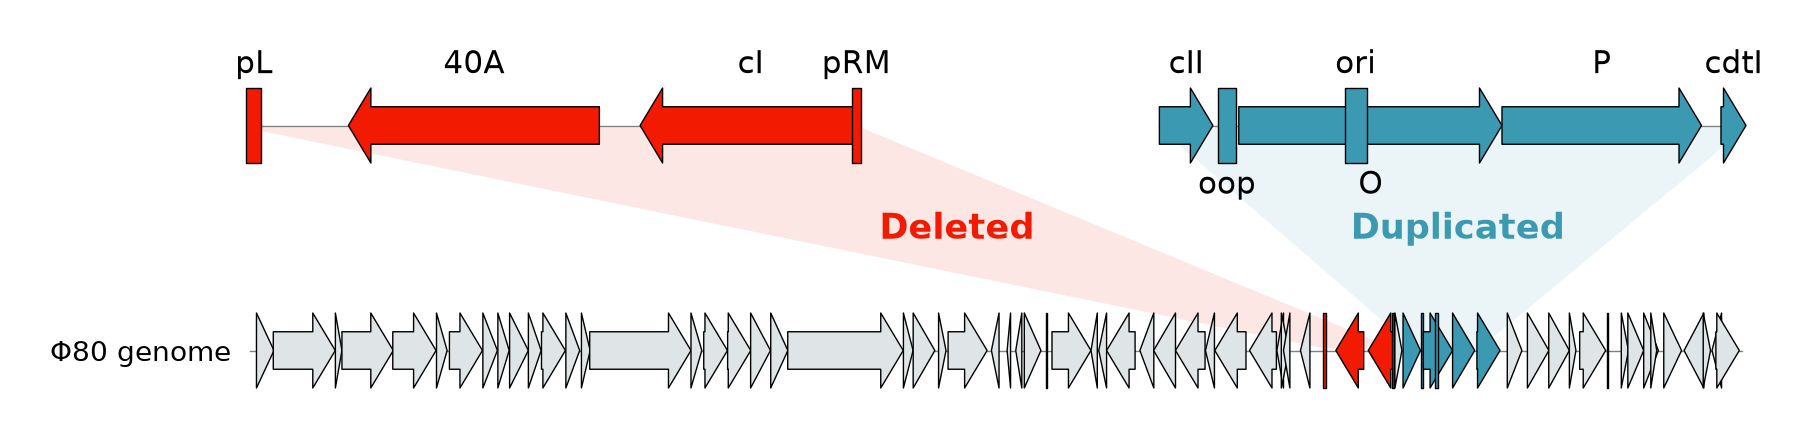

In [23]:
fig = gbv.plotfig()

# Add annotations
#mut_track.ax.text(zoomed_del_len / 2, -1, s=f"region", size=30, color='white', va="top", ha="center")

y = -2.3
label_size = 25
weight = 'book'

mut_track.ax.text(22e3, y, s=f"Deleted", size=label_size, color=pal[4], va="top", ha="center", weight = 'bold')
mut_track.ax.text(37.5e3, y, s=f"Duplicated", size=label_size, color=pal[0], va="top", ha="center", weight = 'bold')

In [24]:
fig.savefig('Plots/genome_plot.pdf')
fig.savefig('Plots/genome_plot.svg')
# figures/static/genome_plot.png (Fig. 4F) is this PNG
fig.savefig('Plots/genome_plot.png', dpi = 300)


# What is in the junction?
Since the deleetion bridges two promoters, it might be creating a new hybrid promoter.
* pL expresses the genes on the left (lysogeny pathway)
* pRM expresses the middle genes (cI/40A) with a positive feedback loop on itself
* pR expresses the genes on the right (lytic pathway) including cII (between deletion and duplication)
* pR' expresses more genes on the right

In [25]:
gene_map_full = pd.read_csv('../../../datasets/phage/phage_identification/phi80_gene_map.tsv', sep = '\t')

print(del_start, del_end)

gene_map_full['deleted'] = (gene_map_full.start >= del_start) & (gene_map_full.end <= del_end)
gene_map_full['partial'] = (gene_map_full.end >= del_start) & (gene_map_full.start <= del_end)

33239 35353


In [26]:
gene_map_full[(gene_map_full.end >= del_start - 1000) & (gene_map_full.start <= del_end + 1000)]

,id,name,start,end,product,fp,N15_homolog,reading_frame,deleted,partial
56,s,NaN,32262,32299,Leftward transcription terminator tL1B,38,NaN,-,False,False
57,s,NaN,32473,32495,Leftward transcription terminator tL1A,23,NaN,-,False,False
58,45,N,32497,32790,Early transcription antiterminator protein N,294,NaN,R2,False,False
59,s,NaN,33078,33089,"CACGTAAACGTG, nutL core (reverse orientation)",12,NaN,-,False,False
60,s,NaN,33134,33142,"TGCTTTTTA, nutL boxA (reverse orientation)",9,NaN,-,False,False
61,s,pL-10,33207,33212,"pL, −10 box",6,NaN,-,False,False
62,s,oL1,33207,33225,oL1,19,NaN,-,False,False
63,s,pL-35,33230,33235,"pL, −35 box",6,NaN,-,False,False
64,s,oL2,33230,33248,oL2,19,NaN,-,False,True
65,s,oL3,33273,33292,oL3,20,NaN,-,True,True


findfont: Failed to find font weight ultralight for DejaVu Sans, now using 400.


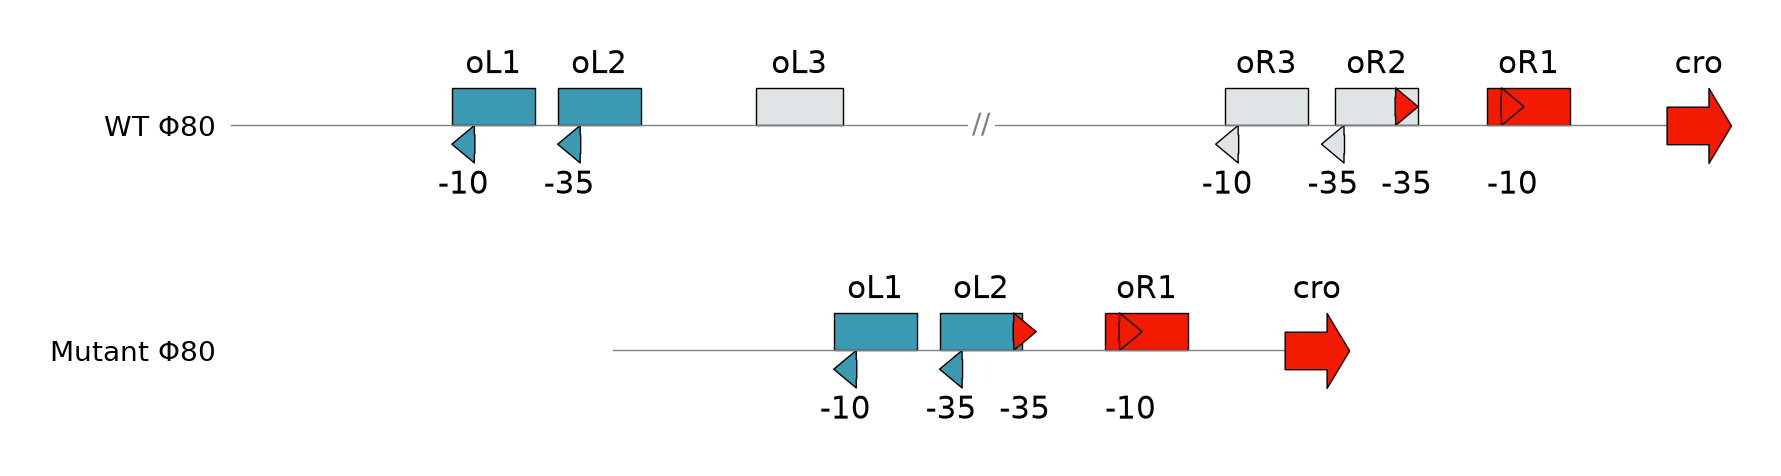

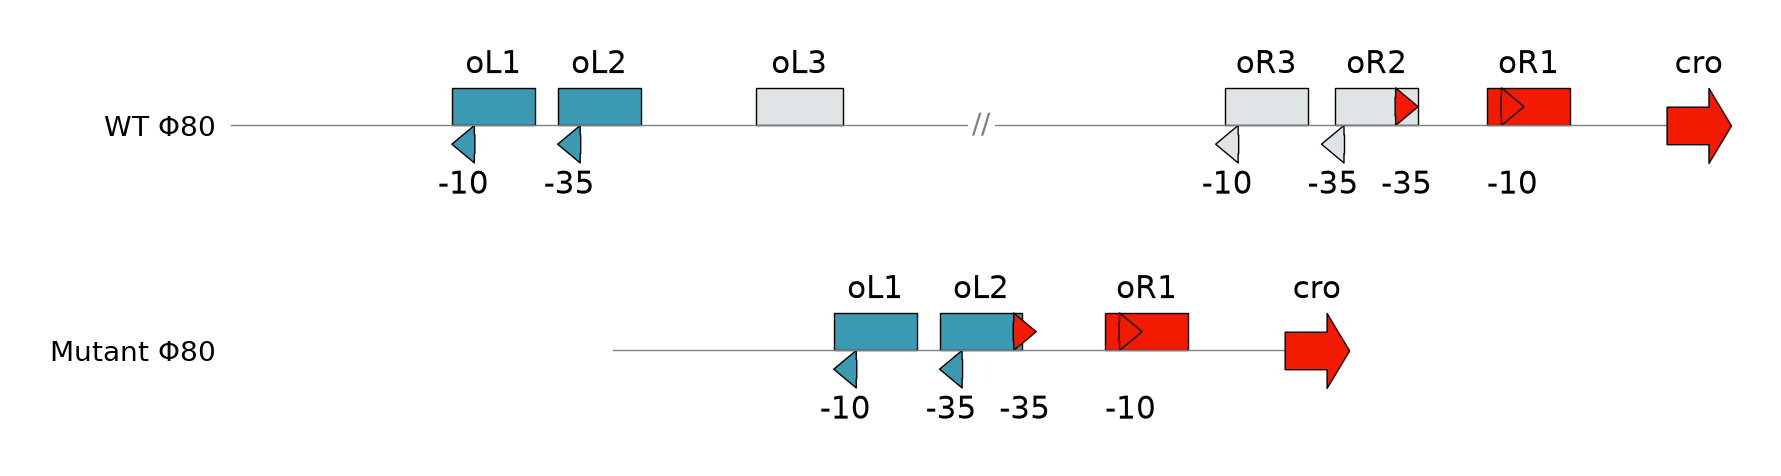

In [27]:
# Deletion of 33239:35353
# Duplication of 36026:38042

# Text style
text_size = 22
main_text_style = dict(rotation=0, vpos = 'top', hpos = 'center', size = text_size)
operator_text_style = dict(rotation=0, vpos = 'center', hpos = 'center', size = text_size, color = 'white')
alt_text_style = dict(rotation=0, vpos = 'bottom', hpos = 'center', size = text_size)

gbv = pygenomeviz.GenomeViz(track_align_type="center", fig_track_height=1, feature_track_ratio=0.5)

wt_name = 'WT Φ80'
mut_name = 'Mutant Φ80'

alt_features = ['O', 'oop']

span = 80 # how many bp to plot on each side

# Create tracks for wild type and mutant
wild_track = gbv.add_feature_track(wt_name, [span * 2, span * 2])
mut_track = gbv.add_feature_track(mut_name, span * 2)

# Add features from dataframe to wild type track
for _, row in df.iterrows():
    
    if row.id == 'x': continue
    
    start, end, name = row[['start', 'end', 'name']]
    
    # Set style
    strand = 1 if str(row['reading_frame']).startswith('F') else (-1 if str(row['reading_frame']).startswith('R') else 0)
    style = 'bigarrow' if strand != 0 else 'bigbox'

    if 'pR' in name: strand = 1
    if 'pRM' in name or 'pL' in name: strand = -1
    
    text_style = main_text_style
    
    if 'oR' in name or 'oL' in name:
        text_style = main_text_style
        style = 'box'
    
    if '-10' in name: 
        name = '-10'
        text_style = alt_text_style
        style = 'arrow'
        
    if '-35' in name: 
        name = '-35'
        text_style = alt_text_style
        style = 'arrow'
        
    # Before deletion: show on L side and mutant
    if start >= del_start - span and start <= del_start:
        
        # Add to WT
        wild_track.segments[0].add_feature(start = start - (del_start - span), end = end - (del_start - span),
                           strand = strand, label = name, text_kws = text_style,
                           plotstyle = style, arrow_shaft_ratio = arrow_shaft_ratio, fc = pal[0], lw = lw)
        
        # Add to mutant
        mut_track.add_feature(start = start - (del_start - span), end = min(end - (del_start - span), del_start),
                           strand = strand, label = name, text_kws = text_style,
                           plotstyle = style, arrow_shaft_ratio = arrow_shaft_ratio, fc = pal[0], lw = lw)
        
    # In deletion, left side
    if start > del_start and start < del_start + span:
        
        # Add to WT
        wild_track.segments[0].add_feature(start = start - (del_start - span), end = end - (del_start - span),
                           strand = strand, label = name, text_kws = text_style,
                           plotstyle = style, arrow_shaft_ratio = arrow_shaft_ratio, fc = other_color, lw = lw)
        
    # In deletion, right side
    if start > del_end - span and start <= del_end:
        
        # Add to WT
        wild_track.segments[1].add_feature(start = start - (del_end - span), end = end - (del_end - span),
                           strand = strand, label = name, text_kws = text_style,
                           plotstyle = style, arrow_shaft_ratio = arrow_shaft_ratio, fc = other_color, lw = lw)
        
    # After deletion
    if start > del_end and start < del_end + span:
        
        # Add to WT
        wild_track.segments[1].add_feature(start = start - (del_end - span), end = min(end - (del_end - span), span * 2),
                           strand = strand, label = name, text_kws = text_style,
                           plotstyle = style, arrow_shaft_ratio = arrow_shaft_ratio, fc = pal[4], lw = lw)
        
        # Add to mutant
        mut_track.add_feature(start = start - (del_end - span), end = min(end - (del_end - span), span * 2),
                           strand = strand, label = name, text_kws = text_style,
                           plotstyle = style, arrow_shaft_ratio = arrow_shaft_ratio, fc = pal[4], lw = lw)      

wild_track.set_segment_sep()
gbv.plotfig()

In [28]:
del_start - span, del_start

(33159, 33239)

In [29]:
row

id                                                  66
name                                                 -
start                                            45352
end                                              46077
product          Conserved hypothetical protein/phiKO2
fp                                                 726
N15_homolog                                       gp59
reading_frame                                       F1
Name: 83, dtype: object